# Passing the Plate: What Really Predicts a Failed Restaurant Inspection in Chicago?

**Anderson Hilliard**
MATH 014 – Introduction to Data Science · Fall 2026 · Howard University

---

## 1. Introduction

Every restaurant, grocery store, school kitchen and daycare that serves food in Chicago is inspected by the
**Chicago Department of Public Health (CDPH)**. Each inspection ends with one of three real outcomes:
**Pass**, **Pass w/ Conditions** (problems found but fixed during the visit), or **Fail**.

**Dataset:** *Food Inspections*, City of Chicago Data Portal (dataset ID `4ijn-s7e5`)
**Source:** https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5
**Downloaded / accessed:** 23 November 2026 (file `Food_Inspections_20261123.csv`)
**Coverage:** 318,725 inspections from 4 January 2010 to 20 November 2026

**Why this is interesting:** the city labels every business as *Risk 1 (High)*, *Risk 2 (Medium)* or *Risk 3 (Low)*
based on the kind of food it handles, and it decides how often to inspect a place from that label. If the labels work,
high-risk places should fail more often. This data lets us test that, and see what else is linked to failing an inspection.

## 2. Objective and Research Questions

**Objective:** find out which recorded factors are linked to a *failed* food inspection in Chicago, using the
**fail rate** (the share of inspections whose result is *Fail*) as the main measure.

| # | Research question | Variables used |
|---|---|---|
| **RQ1** | Do businesses the city labels *High risk* fail inspections more often than *Medium* or *Low* risk ones? | `risk`, `results` |
| **RQ2** | Which of the 10 most-inspected facility types have the highest and lowest fail rates? | `facility_type`, `results` |
| **RQ3** | How does the fail rate change with the **reason** for the inspection (routine canvass, complaint, new license, re-inspection)? | `inspection_type`, `results` |
| **RQ4** | How has the fail rate changed from 2019 to 2026, and is there a seasonal (month-of-year) pattern? | `inspection_date`, `results` |

All four questions are measurable: each one compares fail rates (a percentage) across groups that exist in the data.

## 3. Importing Libraries

* **pandas / numpy**: loading and cleaning the table, and doing calculations
* **matplotlib / seaborn**: static charts
* **plotly express**: interactive charts (hover, zoom, click the legend)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import textwrap   # to shorten long labels

# Make the interactive Plotly charts show up in the notebook AND in the exported HTML file
pio.renderers.default = "plotly_mimetype+notebook_connected"

# One consistent look for every static chart
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110

# Colors I reuse so each result always has the same color
RESULT_COLORS = {"Pass": "#1baf7a", "Pass w/ Conditions": "#eda100", "Fail": "#e34948"}

## 4. Data Loading

The CSV was exported from the Chicago Data Portal and saved in the same folder as this notebook.
`low_memory=False` tells pandas to read the whole file before guessing column types, which avoids warnings
on a file this large.

In [2]:
FILE = "Food_Inspections_20261123.csv"
raw = pd.read_csv(FILE, low_memory=False)

print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (318725, 17)


,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,2647098,STARBUCKS #10634,STARBUCKS #10634,2093900.0,Restaurant,Risk 2 (Medium),3506 S STATE ST,CHICAGO,IL,60609.0,11/20/2026,Canvass,Pass w/ Conditions,"48. WAREWASHING FACILITIES: INSTALLED, MAINTAI...",41.830782,-87.626790,"(41.83078218057412, -87.62679017621963)"
1,2647097,PRINCETON APARTMENTS GOLDEN DINER,MINNIE RIPPERTON APARTMENTS,2225368.0,Golden Diner,Risk 1 (High),4250 S PRINCETON,CHICAGO,IL,60609.0,11/20/2026,Canvass,Pass,NaN,41.816676,-87.633708,"(41.81667584360172, -87.63370847608431)"
2,2647094,Graham,Graham,23391.0,School,Risk 1 (High),4436 S Union (700W),CHICAGO,IL,60609.0,11/20/2026,Canvass Re-Inspection,Pass,NaN,41.813292,-87.643381,"(41.81329195185984, -87.64338050675275)"
3,2647066,COBB HALL,COBB HALL,33346.0,Restaurant,Risk 1 (High),5811 S ELLIS AVE,CHICAGO,IL,60637.0,11/19/2026,Canvass,Pass,NaN,41.789249,-87.601108,"(41.78924933410045, -87.60110843868813)"
4,2647078,DUNKIN,SAII BABA ASHLAND INC,2967294.0,Restaurant,Risk 2 (Medium),4302 S ASHLAND AVE,CHICAGO,IL,60609.0,11/19/2026,Canvass,Pass,49. NON-FOOD/FOOD CONTACT SURFACES CLEAN - Com...,41.815722,-87.665292,"(41.815722227020046, -87.66529164036625)"


## 5. Data Understanding

Before changing anything, I look at the column names, data types, and summary statistics.

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 318725 entries, 0 to 318724
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Inspection ID    318725 non-null  int64  
 1   DBA Name         318725 non-null  str    
 2   AKA Name         316300 non-null  str    
 3   License #        318706 non-null  float64
 4   Facility Type    313366 non-null  str    
 5   Risk             318637 non-null  str    
 6   Address          318725 non-null  str    
 7   City             318541 non-null  str    
 8   State            318649 non-null  str    
 9   Zip              318683 non-null  float64
 10  Inspection Date  318725 non-null  str    
 11  Inspection Type  318724 non-null  str    
 12  Results          318725 non-null  str    
 13  Violations       228658 non-null  str    
 14  Latitude         317660 non-null  float64
 15  Longitude        317660 non-null  float64
 16  Location         317660 non-null  str    
dtypes:

There are 17 columns. Most are text (`str`/`object`). Two things stand out:

* `Inspection Date` is stored as **text**, so it has to be converted to a real date.
* `Zip` and `License #` were read as decimals (`float64`) because they have a few missing values. They are really ID codes, not amounts.

In [4]:
# Summary statistics for the numeric columns
raw.describe().round(2)

,Inspection ID,License #,Zip,Latitude,Longitude
count,318725.00,318706.00,318683.00,317660.00,317660.00
mean,1872311.60,1810643.24,60628.79,41.88,-87.68
std,735365.23,950064.11,199.45,0.08,0.06
min,44247.00,0.00,10014.00,41.64,-87.91
25%,1376043.00,1473482.00,60614.00,41.83,-87.71
50%,2098634.00,2104425.00,60625.00,41.89,-87.67
75%,2560459.00,2464563.25,60643.00,41.94,-87.63
max,2647099.00,9999999.00,91706.00,42.02,-87.53


For `Zip` and `License #`, an average means nothing because they are ID codes. The useful check here is
`Latitude`/`Longitude`: the min and max sit inside the Chicago area (about 41.6–42.0 N, 87.5–87.9 W), so the
locations look valid.

In [5]:
# Summary of the text (categorical) columns: how many unique values, and the most common one
raw.describe(include="object").T

/tmp/ipykernel_143/2236111193.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  raw.describe(include="object").T


,count,unique,top,freq
DBA Name,318725,35319,SUBWAY,4082
AKA Name,316300,33609,SUBWAY,5005
Facility Type,313366,527,Restaurant,216319
Risk,318637,4,Risk 1 (High),237386
Address,318725,33358,11601 W TOUHY AVE,2736
City,318541,96,CHICAGO,317402
State,318649,7,IL,318624
Inspection Date,318725,4253,11/14/2013,185
Inspection Type,318724,110,Canvass,164266
Results,318725,7,Pass,165044


In [6]:
# The outcome variable: what results exist?
raw["Results"].value_counts()

Results
Pass                    165044
Fail                     61360
Pass w/ Conditions       47169
Out of Business          26048
No Entry                 14343
Not Ready                 4665
Business Not Located        96
Name: count, dtype: int64

**Interpretation.** Only three results describe the *food-safety outcome* of a completed inspection: **Pass**,
**Pass w/ Conditions**, and **Fail**. The other four (*Out of Business*, *No Entry*, *Not Ready*,
*Business Not Located*) mean the inspector **could not actually inspect** the place, so they say nothing about how
safe it was. I remove them during cleaning.

In [7]:
raw["Risk"].value_counts(dropna=False)

Risk
Risk 1 (High)      237386
Risk 2 (Medium)     56445
Risk 3 (Low)        24715
All                    91
NaN                    88
Name: count, dtype: int64

Almost every inspection has one of the three risk levels. There are 91 rows labeled `All` (not a real risk level)
and 88 that are missing.

**Relevant analytical features:** `Results` (outcome), `Risk`, `Facility Type`, `Inspection Type`,
`Inspection Date`, `Violations` (text I can count), `Zip`, `Latitude`, `Longitude`, and `DBA Name` (business name).

## 6. Data Cleaning

I work on a copy so the original `raw` table stays untouched.

### 6.1 Standardize column names
Lowercase with underscores (`Inspection Date` → `inspection_date`), so they are easier to type in code.

In [8]:
df = raw.copy()
df.columns = (df.columns.str.strip()
                        .str.lower()
                        .str.replace(" ", "_")
                        .str.replace("#", "number"))
df.columns.tolist()

['inspection_id',
 'dba_name',
 'aka_name',
 'license_number',
 'facility_type',
 'risk',
 'address',
 'city',
 'state',
 'zip',
 'inspection_date',
 'inspection_type',
 'results',
 'violations',
 'latitude',
 'longitude',
 'location']

### 6.2 Parse the date column

In [9]:
# The dates look like 11/20/2026, which is month/day/year
df["inspection_date"] = pd.to_datetime(df["inspection_date"], format="%m/%d/%Y")
print("Earliest:", df["inspection_date"].min().date(), "  Latest:", df["inspection_date"].max().date())

Earliest: 2010-01-04   Latest: 2026-11-20


### 6.3 Check for duplicates

In [10]:
print("Fully duplicated rows:  ", df.duplicated().sum())
print("Repeated inspection IDs:", df["inspection_id"].duplicated().sum())

Fully duplicated rows:   0
Repeated inspection IDs: 0


**Decision:** there are **no** duplicated rows and no repeated `inspection_id` values, so each row is a unique
inspection and nothing needs to be removed. (The same *business* appears many times, and that is expected, since
businesses get inspected repeatedly.)

### 6.4 Filter: keep only real inspection outcomes

In [11]:
REAL_RESULTS = ["Pass", "Pass w/ Conditions", "Fail"]
before = len(df)
df = df[df["results"].isin(REAL_RESULTS)]
print(f"Removed {before - len(df):,} rows where no inspection happened. Rows left: {len(df):,}")

Removed 45,152 rows where no inspection happened. Rows left: 273,573


### 6.5 Filter: inspections from 1 January 2019 onward

**Why:** in **July 2018** Chicago switched to a new food code, and the violation numbers and wording changed
(for example, violation 38 meant something different before). Mixing the old and new systems would make the
violation counts and fail rates hard to compare. Starting on 1 January 2019 gives almost **8 years** of
inspections under one set of rules (through 20 November 2026). It is still well over 100,000 inspections.

In [12]:
before = len(df)
df = df[df["inspection_date"] >= "2019-01-01"]
print(f"Removed {before - len(df):,} older rows. Rows left: {len(df):,}")

Removed 157,773 older rows. Rows left: 115,800


## 7. Missing Values

In [13]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct}).sort_values("missing", ascending=False)

,missing,percent
violations,19924,17.21
location,438,0.38
longitude,438,0.38
latitude,438,0.38
facility_type,139,0.12
aka_name,94,0.08
city,74,0.06
state,42,0.04
zip,4,0.00
license_number,3,0.00


**What I do with each column that has missing values, and why:**

| Column | Decision | Reason |
|---|---|---|
| `violations` | Keep the row and count it as **0 violations** | A blank here means the inspector recorded no violations (most are *Pass*). It is not lost data. |
| `aka_name` | Drop the column | It is just an alternate business name; `dba_name` is complete. |
| `latitude`, `longitude`, `location` | Keep the rows; leave blank | Only needed for the map. The map simply skips rows without coordinates. `location` repeats lat/long, so I drop it. |
| `facility_type` | Fill with `"Unknown"` | Removing the rows would also remove their results from every other question. |
| `risk` | Drop the few rows that are missing or `All` | Only a handful of rows, and RQ1 needs a real risk level. |
| `city`, `state`, `zip` | Drop `city` and `state`; keep `zip` | Every inspection is done by Chicago's own health department, so city/state add nothing (and `city` is full of typos like `CCHICAGO`). |

In [14]:
# Drop columns that are not needed for the analysis
df = df.drop(columns=["aka_name", "location", "city", "state"])

# Facility type: tidy the text, then fill blanks with "Unknown"
df["facility_type"] = df["facility_type"].str.strip().fillna("Unknown")

# Risk: drop rows with a missing or non-standard risk level
before = len(df)
df = df[df["risk"].isin(["Risk 1 (High)", "Risk 2 (Medium)", "Risk 3 (Low)"])]
print("Rows removed for missing/invalid risk:", before - len(df))

Rows removed for missing/invalid risk: 4


### 7.1 Convert types and create new columns

* `zip` and `license_number` become whole-number **ID codes** (pandas `Int64` allows blanks).
* `risk` becomes an **ordered category** (High → Medium → Low), so charts list it in a sensible order.
* New columns:
  * `failed`: 1 if the result is *Fail*, else 0. **The average of this column is the fail rate.**
  * `n_violations`: number of violations written in the report. Violations are separated by ` | `, so the count is
    the number of separators + 1.
  * `violation_codes`: just the violation numbers (e.g. `38;55`), a compact version of the long text.
  * `year`, `month`, `weekday` from the date.

In [15]:
df["zip"] = df["zip"].astype("Int64")
df["license_number"] = df["license_number"].astype("Int64")

df["risk"] = pd.Categorical(df["risk"],
                            categories=["Risk 1 (High)", "Risk 2 (Medium)", "Risk 3 (Low)"],
                            ordered=True)

# 1 = Fail, 0 = Pass or Pass w/ Conditions
df["failed"] = (df["results"] == "Fail").astype(int)

# Count violations: each violation is separated by " | "
def count_violations(text):
    if pd.isna(text):
        return 0
    return text.count(" | ") + 1

df["n_violations"] = df["violations"].apply(count_violations)

# Keep only the violation numbers, e.g. "38. INSECTS, RODENTS... | 55. PHYSICAL..."  ->  "38;55"
df["violation_codes"] = (df["violations"]
                         .str.findall(r"(?:^|\| )(\d+)\. ")   # the number before each ". "
                         .str.join(";"))

df["year"] = df["inspection_date"].dt.year
df["month"] = df["inspection_date"].dt.month
df["weekday"] = df["inspection_date"].dt.day_name()

df[["inspection_date", "results", "failed", "n_violations", "violation_codes"]].head()

,inspection_date,results,failed,n_violations,violation_codes
0,2026-11-20,Pass w/ Conditions,0,1,48
1,2026-11-20,Pass,0,0,NaN
2,2026-11-20,Pass,0,0,NaN
3,2026-11-19,Pass,0,0,NaN
4,2026-11-19,Pass,0,1,49


### 7.2 Group the small facility types

There are many facility types, and most appear only a handful of times (and are spelled in many different ways).
For the comparisons I keep the **10 most common** and put everything else in `"Other"`.

In [16]:
print("Number of different facility types:", df["facility_type"].nunique())

top10_types = df["facility_type"].value_counts().head(10).index
df["facility_group"] = df["facility_type"].where(df["facility_type"].isin(top10_types), "Other")
df["facility_group"].value_counts()

Number of different facility types: 263


facility_group
Restaurant                         79635
Grocery Store                      11973
School                              8507
Other                               4508
Children's Services Facility        4368
Daycare Above and Under 2 Years     1880
Bakery                              1598
Long Term Care                      1151
Daycare (2 - 6 Years)                793
Mobile Food Preparer                 728
Catering                             655
Name: count, dtype: int64

### 7.3 Final check and save the cleaned dataset

In [17]:
print("Final shape:", df.shape)
print("Any duplicated inspection IDs left?", df["inspection_id"].duplicated().any())

# Save the cleaned analysis dataset (the long violations text is replaced by violation_codes to keep the file small)
clean = df.drop(columns=["violations"])
clean.to_csv("anderson_hilliard_final_project.csv", index=False)
print("Saved anderson_hilliard_final_project.csv with", len(clean), "rows")

Final shape: (115796, 20)
Any duplicated inspection IDs left? False


Saved anderson_hilliard_final_project.csv with 115796 rows


## 8. Exploratory Data Analysis (EDA)

### 8.1 Overall outcome

In [18]:
counts = df["results"].value_counts()
percents = (df["results"].value_counts(normalize=True) * 100).round(1)
pd.DataFrame({"inspections": counts, "percent": percents})

,inspections,percent
results,,
Pass,62807,54.2
Pass w/ Conditions,26542,22.9
Fail,26447,22.8


In [19]:
overall_fail = df["failed"].mean()
print(f"Overall fail rate: {overall_fail:.1%}")

Overall fail rate: 22.8%


About **1 in 4.4** completed inspections ends in a *Fail*. I use this **city-wide fail rate** as the reference line in
later charts. Any group above it does worse than average.

### 8.2 Summary statistics of the number of violations

In [20]:
v = df["n_violations"]
q1, q3 = v.quantile(0.25), v.quantile(0.75)
print(f"mean = {v.mean():.2f}, median = {v.median():.0f}, std = {v.std():.2f}")
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {q3 - q1:.0f}, max = {v.max()}")

# Outliers using the 1.5 x IQR rule
upper_fence = q3 + 1.5 * (q3 - q1)
print(f"Outlier cut-off = {upper_fence:.1f} violations -> {(v > upper_fence).sum():,} inspections above it")

mean = 4.05, median = 3, std = 3.93
Q1 = 1, Q3 = 6, IQR = 5, max = 40
Outlier cut-off = 13.5 violations -> 3,656 inspections above it


In [21]:
# Same statistics, split by result
df.groupby("results")["n_violations"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
results,,,,,,,,
Fail,26447.0,7.15,4.70,0.0,4.0,6.0,10.0,40.0
Pass,62807.0,2.17,2.32,0.0,0.0,2.0,3.0,23.0
Pass w/ Conditions,26542.0,5.41,3.57,0.0,3.0,5.0,7.0,30.0


**Interpretation.** A typical inspection records **3** violations (median), but the mean is higher (about 4)
because a few inspections record a very large number (up to 40). That is a **right-skewed** distribution.
Failed inspections have a median of **6** violations, compared with **2** for passes.

Inspections above the 1.5 × IQR fence (more than 13.5 violations) are real but extreme. I keep them, because a very
dirty kitchen is exactly what the inspection system is designed to find.

### 8.3 Fail rate by group (one table per research question)

In [22]:
def fail_table(column):
    """Number of inspections and fail rate (in %) for each value of a column."""
    t = df.groupby(column, observed=True)["failed"].agg(inspections="size", fail_rate="mean")
    t["fail_rate"] = (t["fail_rate"] * 100).round(1)
    return t.sort_values("fail_rate", ascending=False)

fail_table("risk")

,inspections,fail_rate
risk,,
Risk 3 (Low),6017,25.4
Risk 1 (High),92569,22.7
Risk 2 (Medium),17210,22.6


In [23]:
fail_table("facility_group")

,inspections,fail_rate
facility_group,,
Long Term Care,1151,26.7
School,8507,25.3
Bakery,1598,25.3
Grocery Store,11973,25.0
Mobile Food Preparer,728,23.8
Restaurant,79635,22.6
Daycare Above and Under 2 Years,1880,22.1
Daycare (2 - 6 Years),793,21.3
Other,4508,21.2


In [24]:
# Only inspection types with at least 200 inspections, so the rates are not based on tiny groups
it = fail_table("inspection_type")
it[it["inspections"] >= 200]

,inspections,fail_rate
inspection_type,,
Complaint,12474,37.3
Suspected Food Poisoning,216,30.1
License,15812,27.2
Canvass,57141,24.3
Complaint Re-Inspection,5810,14.5
Short Form Complaint,2859,14.2
Recent Inspection,247,13.4
Canvass Re-Inspection,16596,11.3
License Re-Inspection,4556,8.4


In [25]:
fail_table("year").sort_index()

,inspections,fail_rate
year,,
2019,16121,22.4
2020,12600,23.3
2021,13139,23.1
2022,14285,24.9
2023,15412,24.9
2024,15995,21.8
2025,16060,21.1
2026,12184,21.4


**What the tables already suggest (checked with charts below):**

* **Risk level barely changes the fail rate**, and *Low* risk is actually the highest.
* The **reason for the inspection** makes the biggest difference: complaint inspections fail far more often than re-inspections.
* The fail rate rose to about 25% in 2022–2023 and then fell back to about 21%.

### 8.4 Top and bottom: most-inspected businesses

In [26]:
df["dba_name"].str.upper().value_counts().head(10)

dba_name
SUBWAY                     1558
DUNKIN DONUTS               802
MCDONALD'S                  310
CHIPOTLE MEXICAN GRILL      267
JIMMY JOHNS                 241
TACO BELL                   225
WINGSTOP                    210
WENDY'S PROPERTIES, LLC     174
7-ELEVEN                    159
WHOLE FOODS MARKET          148
Name: count, dtype: int64

The most-inspected names are **chains** (Subway, Dunkin', Starbucks, McDonald's). Every location is inspected
separately, so a chain name appears many times. This leads to one of the additional analyses in Section 11.

## 9. Visualizations and Interpretation

Each chart starts with **Intent** (what I want to find out) and ends with an **Interpretation** (what I learned).

### Figure 1 · Univariate: how many violations does an inspection record?
**Intent:** see the shape of the `n_violations` distribution: is it symmetric or skewed, and where does a typical
inspection fall?

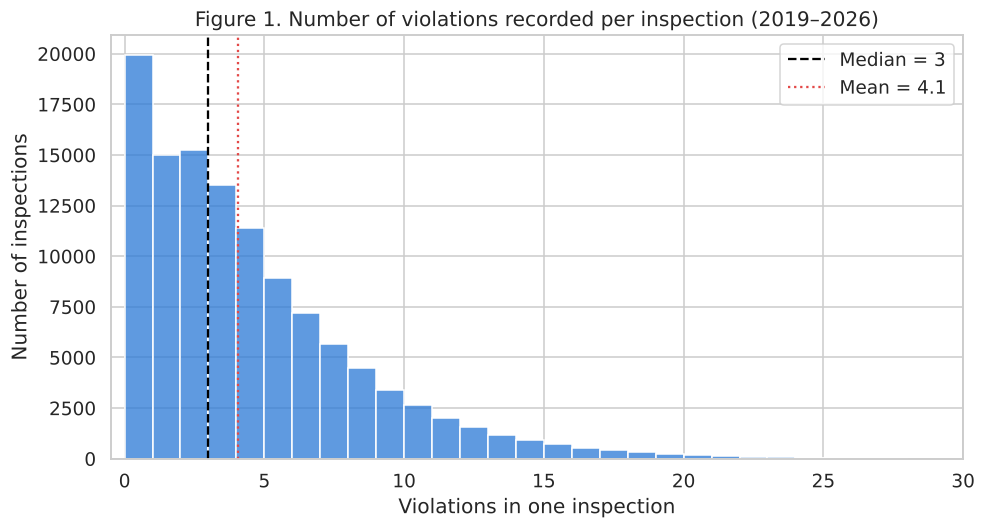

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["n_violations"], binwidth=1, color="#2a78d6", ax=ax)
ax.axvline(df["n_violations"].median(), color="black", linestyle="--",
           label=f"Median = {df['n_violations'].median():.0f}")
ax.axvline(df["n_violations"].mean(), color="#e34948", linestyle=":",
           label=f"Mean = {df['n_violations'].mean():.1f}")
ax.set_title("Figure 1. Number of violations recorded per inspection (2019–2026)")
ax.set_xlabel("Violations in one inspection")
ax.set_ylabel("Number of inspections")
ax.set_xlim(-0.5, 30)
ax.legend()
plt.show()

**Interpretation.** The distribution is strongly **right-skewed**. The tallest bars are at 0–3 violations, and a long tail
stretches past 20. Because of the tail, the mean (about 4.1) sits to the right of the median (3). Most businesses
have a few minor problems. A small number have many.

### Figure 2 · Univariate: how often does each result happen?
**Intent:** show the balance of the outcome variable before comparing groups.

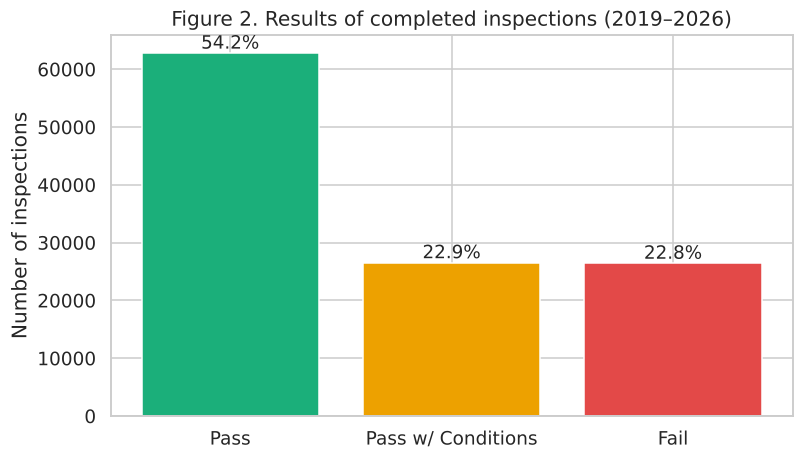

In [28]:
order = ["Pass", "Pass w/ Conditions", "Fail"]
fig, ax = plt.subplots(figsize=(8, 4.5))
counts = df["results"].value_counts().reindex(order)     # counts in Pass -> Fail order
ax.bar(counts.index, counts.values, color=[RESULT_COLORS[r] for r in order])
# Write the percentage on top of each bar
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n / len(df) * 100:.1f}%", ha="center", va="bottom", fontsize=12)
ax.set_title("Figure 2. Results of completed inspections (2019–2026)")
ax.set_xlabel("")
ax.set_ylabel("Number of inspections")
plt.show()

**Interpretation.** A little over half of inspections are a clean **Pass**. The rest split almost evenly between
*Pass w/ Conditions* and *Fail* (about 23% each). So *Fail* is common enough to compare across groups: no group will
have only a handful of failures.

### Figure 3 · Bivariate: number of violations vs. result
**Intent:** check that the result actually reflects how many problems the inspector found. If it does, failed
inspections should sit clearly higher.

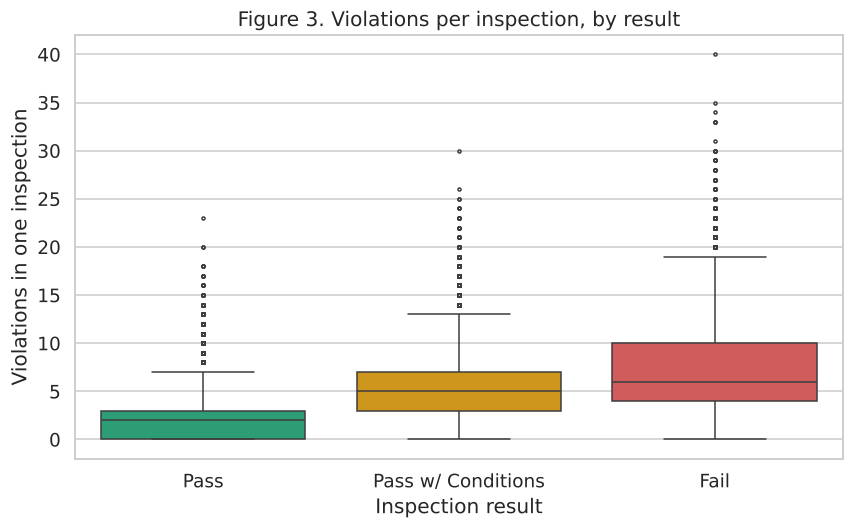

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="results", y="n_violations", order=order, hue="results",
            palette=RESULT_COLORS, legend=False, fliersize=2, ax=ax)
ax.set_title("Figure 3. Violations per inspection, by result")
ax.set_xlabel("Inspection result")
ax.set_ylabel("Violations in one inspection")
plt.show()

**Interpretation.** The three boxes move up step by step: median **2** for Pass, **5** for Pass w/ Conditions, and **6**
for Fail. The boxes overlap, though. Some failed inspections record only 1–2 violations, because a single serious
violation (such as signs of rodents) can fail a business on its own. The *kind* of violation matters, not just the
number. Figure 10 follows that up.

### Figure 4 · RQ1: fail rate by risk category
**Intent:** answer RQ1 directly. Do *High-risk* businesses fail more often?

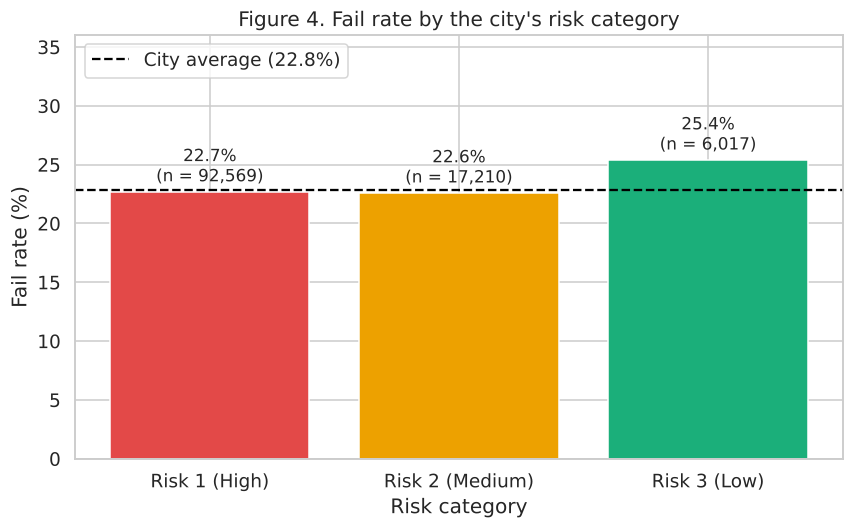

In [30]:
risk_t = fail_table("risk").sort_index()   # sort_index keeps High -> Medium -> Low

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(risk_t.index.astype(str), risk_t["fail_rate"], color=["#e34948", "#eda100", "#1baf7a"])
ax.axhline(overall_fail * 100, color="black", linestyle="--", label=f"City average ({overall_fail:.1%})")
for bar, (rate, n) in zip(bars, zip(risk_t["fail_rate"], risk_t["inspections"])):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.4, f"{rate:.1f}%\n(n = {n:,})",
            ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, 36)
ax.set_title("Figure 4. Fail rate by the city's risk category")
ax.set_ylabel("Fail rate (%)")
ax.set_xlabel("Risk category")
ax.legend(loc="upper left")
plt.show()

**Interpretation.** This is the **surprise of the project**. The three risk levels fail at almost the same rate (about
22.6–25.4%), and **Low-risk businesses fail slightly more often** than High-risk ones. So the risk label is *not* a
prediction of who will fail.

That makes sense once you know what the label is for. It describes **how dangerous the food handling is** (raw meat vs.
packaged snacks) and decides **how often** a place is inspected. It is not a grade of how clean the place is. A
low-risk convenience store can still have mice. The next two cells check what kinds of businesses are in each risk group.

In [31]:
# What kinds of businesses make up each risk level? (percent of each row)
mix = pd.crosstab(df["risk"], df["facility_group"], normalize="index") * 100
mix[["Restaurant", "Grocery Store", "School", "Other"]].round(1)

facility_group,Restaurant,Grocery Store,School,Other
risk,,,,
Risk 1 (High),72.5,5.7,8.6,2.7
Risk 2 (Medium),66.7,17.8,2.2,5.0
Risk 3 (Low),18.0,60.1,2.6,18.9


In [32]:
# Is Low risk still higher when we compare the SAME kind of inspection?
same_type = df[df["inspection_type"].isin(["Canvass", "Complaint"])]
(same_type.pivot_table(index="risk", columns="inspection_type", values="failed",
                       aggfunc="mean", observed=True) * 100).round(1)

inspection_type,Canvass,Complaint
risk,,
Risk 1 (High),24.6,37.0
Risk 2 (Medium),21.2,36.5
Risk 3 (Low),27.8,46.1


**Explanation found.** High-risk inspections are mostly **restaurants** (about 72%), while about **60%** of Low-risk
inspections are **grocery and convenience stores**, which have an above-average fail rate (Figure 5). Low-risk places
still fail more even within the *same* inspection type (routine canvass or complaint). Packaged-food stores are less
dangerous *per item*, but they are just as likely to have dirty floors or pests, and those cause most failures
(see Figure 10).

### Figure 5 · RQ2: fail rate by facility type
**Intent:** rank the 10 most-inspected facility types (plus *Other* and *Unknown*) by fail rate and compare them to the city average.

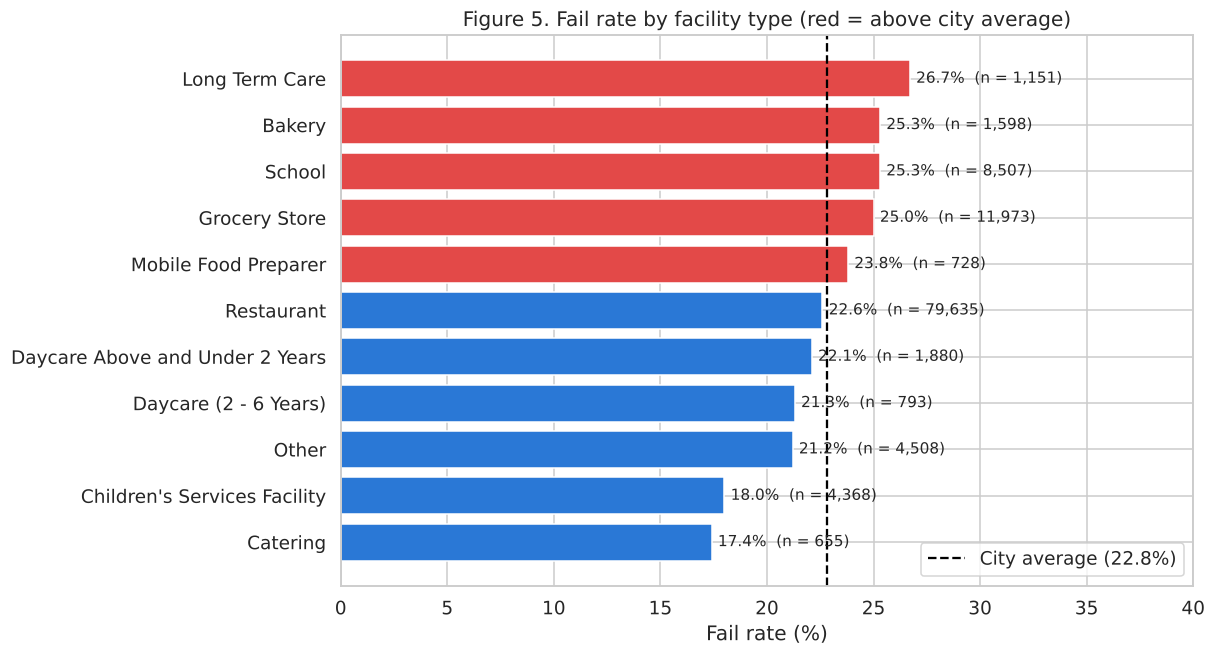

In [33]:
fac = fail_table("facility_group").sort_values("fail_rate")

fig, ax = plt.subplots(figsize=(10, 6.5))
colors = ["#e34948" if r > overall_fail * 100 else "#2a78d6" for r in fac["fail_rate"]]
ax.barh(fac.index, fac["fail_rate"], color=colors)
ax.axvline(overall_fail * 100, color="black", linestyle="--", label=f"City average ({overall_fail:.1%})")
for y, (rate, n) in enumerate(zip(fac["fail_rate"], fac["inspections"])):
    ax.text(rate + 0.3, y, f"{rate:.1f}%  (n = {n:,})", va="center", fontsize=10)
ax.set_xlim(0, 40)
ax.set_title("Figure 5. Fail rate by facility type (red = above city average)")
ax.set_xlabel("Fail rate (%)")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.show()

**Interpretation.** Facilities serving **children** (Children's Services Facilities, daycares) and **catering** have the
lowest fail rates, below 23%. **Long-term care facilities, schools, bakeries and grocery stores** are above average
(about 25–27%). **Restaurants** make up about two-thirds of all inspections and sit right at the city average, so they
largely *set* that average. The gap between best and worst is about 9 percentage points. That is real, but smaller
than the gaps in RQ3.

### Figure 6 · RQ3 (Interactive #1 · Plotly bar): fail rate by reason for inspection
**Intent:** compare fail rates across inspection types. **Hover** over a bar to see the exact number of inspections and failures.

In [34]:
it = (df.groupby("inspection_type")["failed"]
        .agg(inspections="size", fails="sum", fail_rate="mean")
        .reset_index())
it = it[it["inspections"] >= 200].sort_values("fail_rate")   # ignore tiny groups
it["fail_rate_pct"] = (it["fail_rate"] * 100).round(1)

fig = px.bar(it, x="fail_rate_pct", y="inspection_type", orientation="h",
             color="fail_rate_pct", color_continuous_scale="Reds",
             hover_data={"inspections": ":,", "fails": ":,", "fail_rate_pct": ":.1f",
                         "inspection_type": False},
             labels={"fail_rate_pct": "Fail rate (%)", "inspection_type": "Inspection type",
                     "inspections": "Inspections", "fails": "Failed"},
             title="Figure 6. Fail rate by reason for inspection (hover for counts)")
fig.add_vline(x=overall_fail * 100, line_dash="dash",
              annotation_text=f"City average {overall_fail:.1%}", annotation_position="top")
fig.update_layout(height=500, coloraxis_showscale=False)
fig.show()

**Interpretation.** The **reason** for the visit is the strongest pattern in the project:

* **Complaint** inspections fail **37%** of the time. When the public reports a problem, there usually is one.
* First-time **License** inspections (27%) and routine **Canvass** visits (24%) are near or a bit above average.
* **Re-inspections** have the lowest rates (about 8–15%). After failing, most businesses fix the problem before the inspector returns.

The difference between complaint inspections and license re-inspections is about **29 percentage points**, more than three
times the gap between facility types.

### Figure 7 · RQ4: fail rate over time
**Intent:** see whether food safety in Chicago has been getting better or worse year by year. I also check whether
the trend is the same for the three most common inspection types, since Figure 6 showed they behave differently.

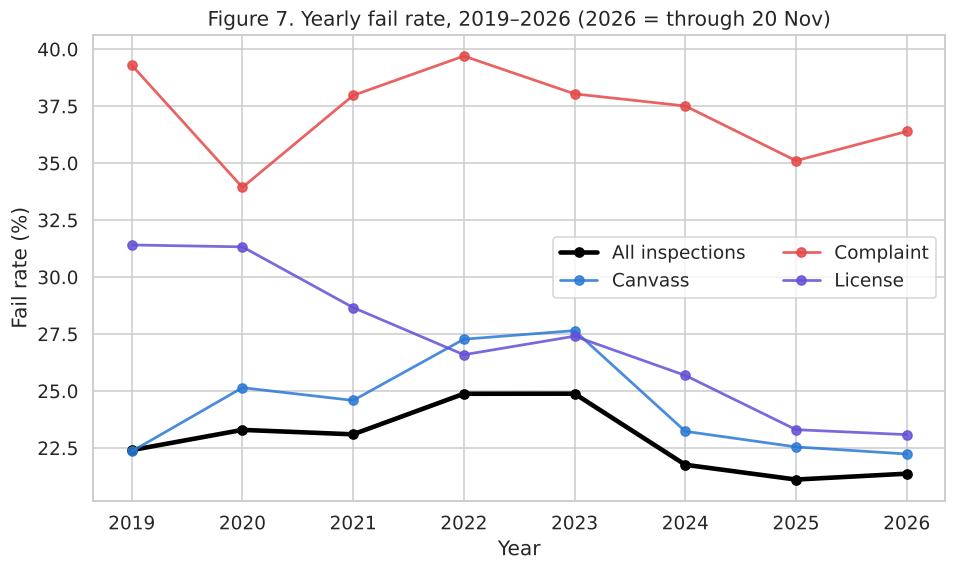

In [35]:
yearly = df.groupby("year")["failed"].mean() * 100
main_types = ["Canvass", "Complaint", "License"]
by_type = (df[df["inspection_type"].isin(main_types)]
           .groupby(["year", "inspection_type"])["failed"].mean().unstack() * 100)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(yearly.index, yearly.values, color="black", linewidth=3, marker="o", label="All inspections")
for t, c in zip(main_types, ["#2a78d6", "#e34948", "#6250d6"]):
    ax.plot(by_type.index, by_type[t], color=c, linewidth=1.8, marker="o", alpha=0.85, label=t)
ax.set_title("Figure 7. Yearly fail rate, 2019–2026 (2026 = through 20 Nov)")
ax.set_xlabel("Year")
ax.set_ylabel("Fail rate (%)")
ax.set_xticks(yearly.index)
ax.legend(ncol=2)
plt.show()

**Interpretation.** The overall fail rate climbed from about **22%** in 2019 to a peak of about **25%** in 2022–2023,
then dropped to about **21%** in 2024–2026. The lines by type show **where** that bump comes from. Routine
**Canvass** inspections rose from about 22% to almost 28% in 2022–2023 and then fell back to about 22%. **License**
inspections improved steadily, from about 31% in 2019 to 23% in 2026. **Complaint** inspections stay far above the
others every single year (34–40%), so the RQ3 finding is stable over time.

### Figure 8 · Multivariate heatmap: year × month × fail rate
**Intent:** look at three variables at once (year, month, and fail rate as color) to see whether there is a
**seasonal** pattern that repeats every year. I use the full years 2019–2025 so every cell has a complete month.

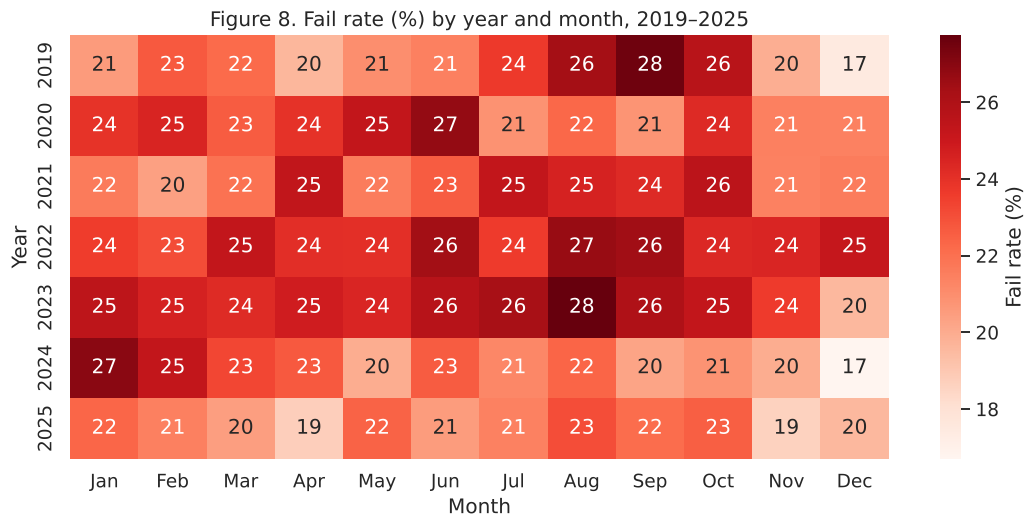

Jan    23.5
Feb    23.2
Mar    22.9
Apr    22.8
May    22.7
Jun    23.7
Jul    23.2
Aug    24.7
Sep    23.9
Oct    24.1
Nov    21.3
Dec    20.2
dtype: float64

In [36]:
full_years = df[df["year"] <= 2025]
heat = full_years.pivot_table(index="year", columns="month", values="failed", aggfunc="mean") * 100
heat.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "Fail rate (%)"}, ax=ax)
ax.set_title("Figure 8. Fail rate (%) by year and month, 2019–2025")
ax.set_xlabel("Month")
ax.set_ylabel("Year")
plt.show()

# Average across all years for each month
(heat.mean() ).round(1)

**Interpretation.** Two patterns show up:

1. **Rows:** 2022 and 2023 are the darkest rows, the same peak seen in Figure 7.
2. **Columns:** late summer and early fall (**Aug–Oct**) tend to be darker, and **December** is usually the lightest month.
   Warm weather is when pests and keeping food cold are harder, which fits the top failure reasons in Figure 10.

The seasonal effect is mild (a few percentage points) compared with the effect of inspection type.

### Figure 9 · Interactive #2 (Plotly map): fail rate by ZIP code
**Intent:** see whether failures cluster in certain parts of the city. Each bubble is a ZIP code placed at the average
location of its inspections. **Bubble size = number of inspections; color = fail rate.** Hover for details, and
scroll to zoom.

In [37]:
geo = df.dropna(subset=["latitude", "longitude", "zip"])
by_zip = (geo.groupby("zip")
             .agg(inspections=("failed", "size"), fail_rate=("failed", "mean"),
                  lat=("latitude", "mean"), lon=("longitude", "mean"))
             .reset_index())
by_zip = by_zip[by_zip["inspections"] >= 100]           # skip ZIPs with very few inspections
by_zip["fail_rate_pct"] = (by_zip["fail_rate"] * 100).round(1)
by_zip["zip"] = by_zip["zip"].astype(str)

fig = px.scatter_map(by_zip, lat="lat", lon="lon", size="inspections", color="fail_rate_pct",
                     color_continuous_scale="RdYlGn_r", size_max=28, zoom=9.2,
                     center={"lat": 41.84, "lon": -87.68}, map_style="carto-positron",
                     hover_name="zip",
                     hover_data={"inspections": ":,", "fail_rate_pct": ":.1f", "lat": False, "lon": False},
                     labels={"fail_rate_pct": "Fail rate (%)", "inspections": "Inspections"},
                     title="Figure 9. Fail rate by ZIP code (ZIPs with 100+ inspections)")
fig.update_layout(height=650)
fig.show()

print("Highest-fail ZIPs:")
print(by_zip.sort_values("fail_rate_pct", ascending=False)[["zip", "inspections", "fail_rate_pct"]].head(5).to_string(index=False))
print("\nLowest-fail ZIPs:")
print(by_zip.sort_values("fail_rate_pct")[["zip", "inspections", "fail_rate_pct"]].head(5).to_string(index=False))

Highest-fail ZIPs:
  zip  inspections  fail_rate_pct
60617         2419           32.1
60620         2298           31.5
60621          965           31.1
60619         2247           29.9
60639         3137           28.9

Lowest-fail ZIPs:
  zip  inspections  fail_rate_pct
60666         1613           10.8
60606         1518           14.4
60638         1740           14.9
60661         1335           16.1
60601         1792           17.0


**Interpretation.** Fail rates are **not the same everywhere**. They range from about **11%** to **32%** across ZIP codes,
and there is a visible **geographic pattern**:

* The **highest** rates cluster on the **South Side** (60617, 60620, 60621, 60619, all around 30–32%).
* The **lowest** rates are at **O'Hare Airport** (60666, about 11%) and in the **Loop/downtown** (60606, 60661, 60601), where many
  businesses are newer buildings and chains.

This map shows *where* failures are more common, not *why*. Building age, the mix of business types, and
neighborhood resources could all play a role, and this dataset cannot separate them. Section 12 lists it as a
future investigation.

### Figure 10 · Surprise plot: what are failing businesses actually cited for?
**Intent:** most people picture a failed inspection as spoiled food or raw chicken left out. I check which violations
show up most often in **failed** inspections.

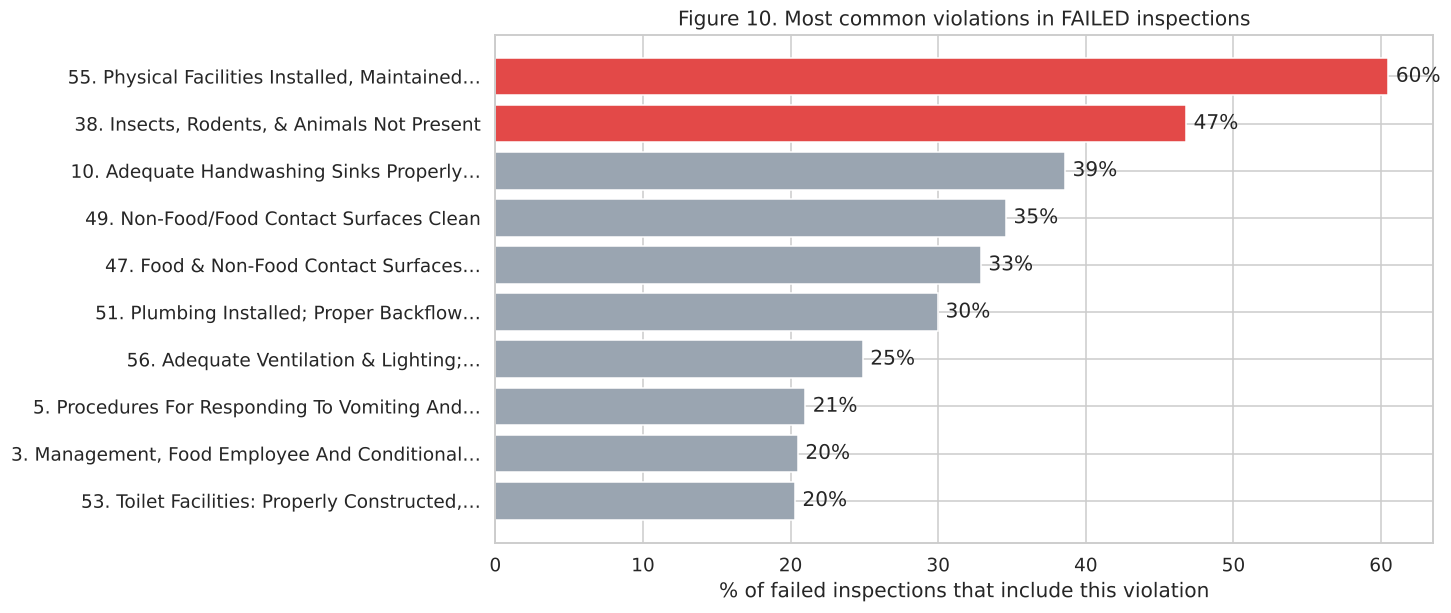

,code,label,pct_of_fails
0,55,"55. Physical Facilities Installed, Maintained…",60.5
1,38,"38. Insects, Rodents, & Animals Not Present",46.8
2,10,10. Adequate Handwashing Sinks Properly…,38.6
3,49,49. Non-Food/Food Contact Surfaces Clean,34.6
4,47,47. Food & Non-Food Contact Surfaces…,32.9
5,51,51. Plumbing Installed; Proper Backflow…,30.0
6,56,56. Adequate Ventilation & Lighting;…,24.9
7,5,5. Procedures For Responding To Vomiting And…,21.0
8,3,"3. Management, Food Employee And Conditional…",20.5
9,53,"53. Toilet Facilities: Properly Constructed,…",20.3


In [38]:
# Each failed inspection lists several codes like "38;55;10" -> split them into one row per code
fail_codes = (df.loc[df["failed"] == 1, "violation_codes"]
                .dropna()
                .str.split(";")
                .apply(lambda codes: list(set(codes)))   # count each code only once per inspection
                .explode())

# Build a lookup from code number to its short description, using the original violation text
names = (df["violations"].dropna().str.split(r" \| ").explode()
           .str.extract(r"^(\d+)\.\s*(.*?)\s*- Comments")
           .dropna()
           .drop_duplicates(subset=0)
           .set_index(0)[1])

n_fails = df["failed"].sum()
top = fail_codes.value_counts().head(10)
top_df = pd.DataFrame({"code": top.index,
                       "pct_of_fails": (top.values / n_fails * 100).round(1)})
# Shorten long descriptions at a whole word, e.g. "PHYSICAL FACILITIES INSTALLED..." -> "Physical Facilities Installed…"
top_df["label"] = [code + ". " + textwrap.shorten(names[code].title(), width=42, placeholder="…")
                   for code in top_df["code"]]

# Highlight the two "building and pests" violations that dominate
highlight = {"55", "38"}
colors = ["#e34948" if c in highlight else "#9aa5b1" for c in top_df["code"]]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top_df["label"][::-1], top_df["pct_of_fails"][::-1], color=colors[::-1])
for y, p in enumerate(top_df["pct_of_fails"][::-1]):
    ax.text(p + 0.5, y, f"{p:.0f}%", va="center")
ax.set_title("Figure 10. Most common violations in FAILED inspections")
ax.set_xlabel("% of failed inspections that include this violation")
plt.show()
top_df[["code", "label", "pct_of_fails"]]

**Interpretation.** The most common citation in a failed inspection is **not about food at all**. Violation **55**
(*physical facilities not maintained and clean*, meaning floors, walls and ceilings) appears in the **majority** of failed
inspections (61%). Next is **38** (*insects, rodents and animals*), in almost half (47%). Hand-washing sinks (**10**) come third (39%).
Food-temperature problems are not in the top three.

**Insight:** a business is most likely to fail because of the **building**, specifically cleanliness and pests, rather
than how the food itself is cooked. That gives business owners a very concrete target.

## 10. Research Questions: Answers

| RQ | Answer |
|---|---|
| **RQ1** Does high risk mean more failures? | **No.** High, Medium and Low risk all fail about 23–25% of the time, and Low risk is slightly *highest* (Fig. 4). The label measures food-handling danger and sets inspection frequency. It does not predict cleanliness. |
| **RQ2** Which facility types fail most and least? | Highest: **Long-Term Care, Schools, Bakeries, Grocery Stores** (≈25–27%). Lowest: **Children's Services, Catering, Daycares** (≈17–22%). Restaurants ≈ average (Fig. 5). |
| **RQ3** Does the reason for inspection matter? | **Yes, it matters most.** Complaint inspections fail ≈37%, routine canvasses ≈24%, re-inspections only ≈8–15% (Fig. 6). |
| **RQ4** Trend and seasonality? | Fail rate rose from ≈22% (2019) to ≈25% (2022–23), then fell to ≈21% (2024–26). Mild seasonality: higher Aug–Oct, lowest in December (Figs. 7–8). |

## 11. Additional Analyses (beyond the main research questions)

### 11.1 Do big chains fail less than the city average?
**Why I looked:** Section 8.4 showed that chains are the most-inspected names. Chains have corporate training and
standard procedures, so I wanted to see whether that shows up in their fail rates.

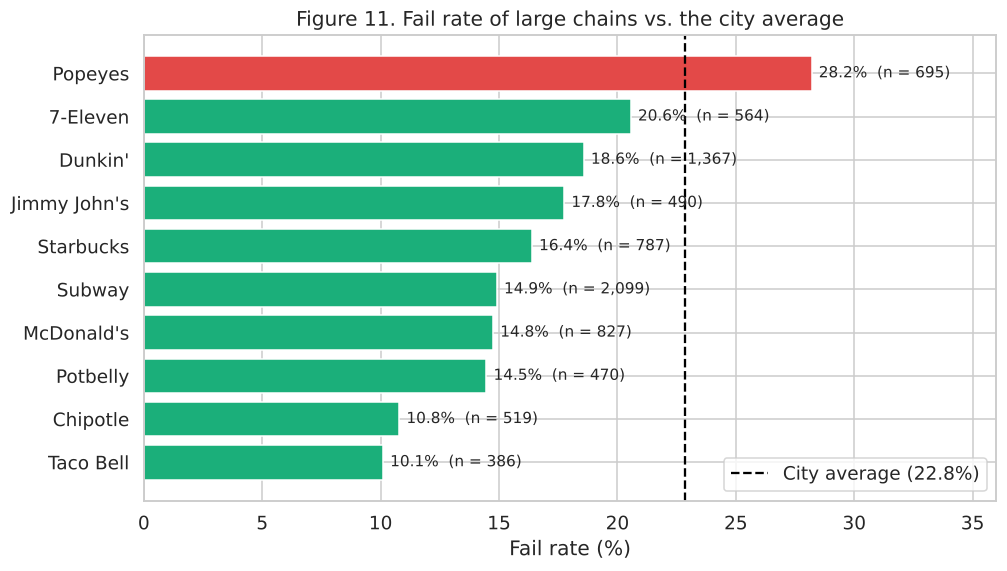

In [39]:
# search text -> name to show on the chart
chains = {"SUBWAY": "Subway", "MCDONALD": "McDonald's", "STARBUCKS": "Starbucks",
          "DUNKIN": "Dunkin'", "CHIPOTLE": "Chipotle", "7-ELEVEN": "7-Eleven",
          "POTBELLY": "Potbelly", "JIMMY JOHN": "Jimmy John's", "POPEYE": "Popeyes",
          "TACO BELL": "Taco Bell"}

name_upper = df["dba_name"].str.upper()
rows = []
for search, label in chains.items():
    mask = name_upper.str.contains(search, regex=False)      # e.g. "SUBWAY #1234" contains "SUBWAY"
    rows.append({"chain": label, "inspections": mask.sum(),
                 "fail_rate": df.loc[mask, "failed"].mean() * 100})
chain_t = pd.DataFrame(rows).sort_values("fail_rate")

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ["#e34948" if r > overall_fail * 100 else "#1baf7a" for r in chain_t["fail_rate"]]
ax.barh(chain_t["chain"], chain_t["fail_rate"], color=colors)
ax.axvline(overall_fail * 100, color="black", linestyle="--", label=f"City average ({overall_fail:.1%})")
for y, (r, n) in enumerate(zip(chain_t["fail_rate"], chain_t["inspections"])):
    ax.text(r + 0.3, y, f"{r:.1f}%  (n = {n:,})", va="center", fontsize=10)
ax.set_xlim(0, 36)
ax.set_title("Figure 11. Fail rate of large chains vs. the city average")
ax.set_xlabel("Fail rate (%)")
ax.legend(loc="lower right")
plt.show()

**What I learned.** **9 of the 10 chains fail less often than the city average.** Taco Bell and Chipotle fail only about
10–11% of the time, roughly half the city rate. The exception is **Popeyes** (≈28%), which is *above* average.
Standardized corporate procedures seem to help, but a famous brand alone does not guarantee a clean kitchen.
(Caveat: the name matching is simple text search, so a non-chain with a similar name could be counted.)

### 11.2 What happens after a business fails?
**Why I looked:** Figure 6 showed re-inspections rarely fail. I wanted to measure this more directly: for every
failed inspection, what was the **next** result for that same business (same license number)?

Failed inspections that have a later inspection: 26,041


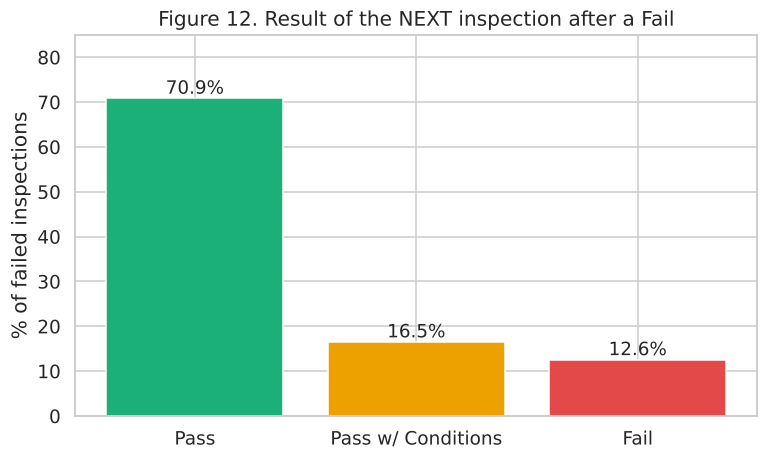

next_result
Pass                  70.9
Pass w/ Conditions    16.5
Fail                  12.6
Name: proportion, dtype: float64

In [40]:
# Sort each business's inspections by date, then look at the result of its NEXT inspection
hist = df.dropna(subset=["license_number"]).sort_values(["license_number", "inspection_date"])
hist["next_result"] = hist.groupby("license_number")["results"].shift(-1)

after_fail = hist[(hist["results"] == "Fail") & hist["next_result"].notna()]
next_share = after_fail["next_result"].value_counts(normalize=True).reindex(order) * 100
print(f"Failed inspections that have a later inspection: {len(after_fail):,}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(next_share.index, next_share.values, color=[RESULT_COLORS[r] for r in next_share.index])
for i, p in enumerate(next_share.values):
    ax.text(i, p + 1, f"{p:.1f}%", ha="center", fontsize=12)
ax.set_ylim(0, 85)
ax.set_title("Figure 12. Result of the NEXT inspection after a Fail")
ax.set_ylabel("% of failed inspections")
plt.show()
next_share.round(1)

**What I learned.** After a failure, about **7 in 10** businesses get a clean **Pass** next time, and only about **1 in 8**
fail again. The inspection system works as intended: failing leads to fixes. The small group that fails repeatedly
would be a good focus for the city's attention.

## 12. Insights and Conclusion

**Were the research questions answered?** Yes. All four were answered with fail rates computed from more than 115,000
completed inspections (Section 10).

**Main insights**

1. **The city's risk label is not a warning sign of failure.** High, Medium and Low risk businesses fail at nearly the same rate.
   The label describes the *food* a business handles and how often it is inspected, not how clean it is.
2. **Why the inspector came matters more than what kind of place it is.** Complaint inspections fail at 37%, about three
   times the rate of license re-inspections. Public complaints are a strong signal of real problems.
3. **Buildings and pests, not food, are the top reason for failing.** Dirty facilities (55) and pests (38) appear in most failed inspections.
4. **Location matters too.** Several South Side ZIP codes fail around 30–32% of inspections, compared with about 11–17%
   at O'Hare and downtown (Figure 9).
5. **Chicago improved after a post-pandemic peak.** The fail rate rose to about 25% in 2022–2023 and has fallen to about 21% since 2024.
6. **Failing works as a wake-up call.** About 87% of businesses pass (with or without conditions) on their next inspection.

**Limitations**

* The data shows **association, not cause**. For example, complaint inspections fail more, but complaints are not random.
* Inspection standards and inspectors can differ, so part of the variation may come from *who* inspected, which the data does not record.
* `facility_type` has many inconsistent spellings. I only analyzed the 10 largest types, so smaller groups are combined into *Other*.
* Chain detection is simple name matching and may include a few non-chain businesses.
* 2026 is a partial year (through 20 November).
* Rows without coordinates (under 1%) are left out of the map.

**Future investigations**

* Build a simple model (for example, logistic regression) that predicts *Fail* from inspection type, facility type, month and past results.
* Combine with Census data by ZIP code to see whether neighborhood income is related to fail rates.
* Follow individual businesses over time to find "repeat offenders" and see whether they eventually close.